In [2]:
import os
import torch
import torchaudio
from torchaudio.datasets import SPEECHCOMMANDS

os.makedirs("./data", exist_ok=True)

class SubsetSC(SPEECHCOMMANDS):
    def __init__(self, subset: str = None):
        super().__init__("./data", download=True)
        def load_list(filename):
            filepath = os.path.join(self._path, filename)
            with open(filepath) as fileobj:
                return [os.path.normpath(os.path.join(self._path, line.strip())) for line in fileobj]

        if subset == "validation":
            self._walker = load_list("validation_list.txt")
        elif subset == "testing":
            self._walker = load_list("testing_list.txt")
        elif subset == "training":
            excludes = set(load_list("validation_list.txt") + load_list("testing_list.txt"))
            self._walker = [w for w in self._walker if w not in excludes]

train_set = SubsetSC("training")
val_set = SubsetSC("validation")
test_set = SubsetSC("testing")

labels = sorted(list(set(datapoint[2] for datapoint in train_set)))
print(f"Train: {len(train_set)}, Val: {len(val_set)}, Test: {len(test_set)}, Classes: {len(labels)}")

100%|██████████| 2.26G/2.26G [00:22<00:00, 110MB/s]


Train: 84843, Val: 9981, Test: 11005, Classes: 35


In [3]:
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

SAMPLE_RATE = 16000
NUM_SAMPLES = 16000

mel_spectrogram = torchaudio.transforms.MelSpectrogram(
    sample_rate=SAMPLE_RATE, n_fft=1024, hop_length=256, n_mels=64
)
amplitude_to_db = torchaudio.transforms.AmplitudeToDB()

# SpecAugment (randomly blocks small stripes to make the AI smarter)
freq_mask = torchaudio.transforms.FrequencyMasking(freq_mask_param=8)
time_mask = torchaudio.transforms.TimeMasking(time_mask_param=16)

def collate_fn(batch, is_train=False):
    tensors, targets = [], []
    for waveform, _, label, *_ in batch:
        if waveform.shape[1] < NUM_SAMPLES:
            waveform = F.pad(waveform, (0, NUM_SAMPLES - waveform.shape[1]))
        else:
            waveform = waveform[:, :NUM_SAMPLES]

        spec = amplitude_to_db(mel_spectrogram(waveform))
        if is_train:
            spec = time_mask(freq_mask(spec))
        tensors.append(spec)
        targets.append(labels.index(label))
    return torch.stack(tensors), torch.tensor(targets)

train_loader = DataLoader(train_set, batch_size=128, shuffle=True, collate_fn=lambda b: collate_fn(b, True), num_workers=2)
val_loader = DataLoader(val_set, batch_size=128, shuffle=False, collate_fn=lambda b: collate_fn(b, False), num_workers=2)
test_loader = DataLoader(test_set, batch_size=128, shuffle=False, collate_fn=lambda b: collate_fn(b, False), num_workers=2)

print("DataLoaders ready! Batch shape:", next(iter(train_loader))[0].shape)

DataLoaders ready! Batch shape: torch.Size([128, 1, 64, 63])


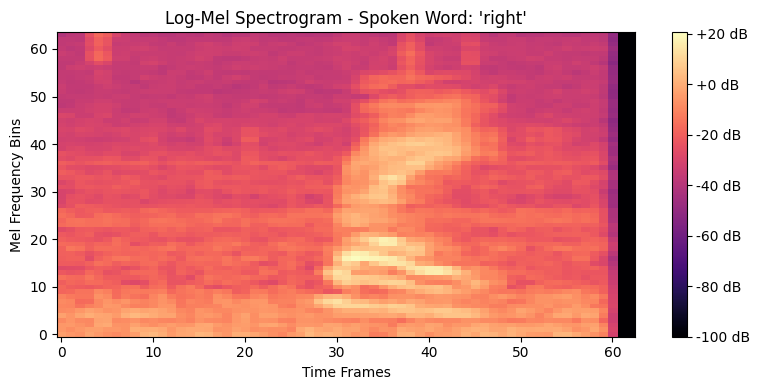

Epoch 01/15 | Validation Accuracy: 66.33%


KeyboardInterrupt: 

In [4]:
import matplotlib.pyplot as plt

# 1. Plot and save a sample Spectrogram picture for your GitHub README
sample_spec, sample_label = next(iter(val_loader))
plt.figure(figsize=(8, 4))
plt.imshow(sample_spec[0][0].numpy(), origin="lower", aspect="auto", cmap="magma")
plt.title(f"Log-Mel Spectrogram - Spoken Word: '{labels[sample_label[0]]}'")
plt.xlabel("Time Frames")
plt.ylabel("Mel Frequency Bins")
plt.colorbar(format="%+2.0f dB")
plt.tight_layout()
plt.savefig("sample_spectrogram.png", dpi=150)
plt.show()

# 2. Define the 4-layer 2D CNN
class AudioCNN(nn.Module):
    def __init__(self, num_classes=35):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(128, 256, kernel_size=3, padding=1), nn.BatchNorm2d(256), nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.fc = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.conv(x)
        return self.fc(x.view(x.size(0), -1))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = AudioCNN(len(labels)).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

# 3. Train for 15 Epochs
for epoch in range(15):
    model.train()
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()

    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(device), y.to(device)
            preds = model(x).argmax(dim=1)
            correct += (preds == y).sum().item()
            total += y.size(0)
    print(f"Epoch {epoch+1:02d}/15 | Validation Accuracy: {100 * correct / total:.2f}%")

torch.save(model.state_dict(), "audiocnn_mel_specaug.pth")
print("Training complete! Model saved.")

In [5]:
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Pre-compute all spectrograms ONCE onto GPU/RAM (~1-2 mins total)
def cache_dataset(dataset, desc=""):
    specs, targets = [], []
    mel_gpu = mel_spectrogram.to(device)
    db_gpu = amplitude_to_db.to(device)

    with torch.no_grad():
        for i in range(len(dataset)):
            waveform, _, label, *_ = dataset[i]
            if waveform.shape[1] < NUM_SAMPLES:
                waveform = F.pad(waveform, (0, NUM_SAMPLES - waveform.shape[1]))
            else:
                waveform = waveform[:, :NUM_SAMPLES]
            spec = db_gpu(mel_gpu(waveform.to(device))).cpu()
            specs.append(spec)
            targets.append(labels.index(label))
    print(f"Cached {desc}: {len(specs)} clips")
    return TensorDataset(torch.stack(specs), torch.tensor(targets))

t0 = time.time()
train_cached = cache_dataset(train_set, "Train")
val_cached = cache_dataset(val_set, "Validation")
test_cached = cache_dataset(test_set, "Test")
print(f"All datasets cached in {time.time() - t0:.1f}s!")

fast_train_loader = DataLoader(train_cached, batch_size=256, shuffle=True)
fast_val_loader = DataLoader(val_cached, batch_size=256, shuffle=False)
fast_test_loader = DataLoader(test_cached, batch_size=256, shuffle=False)

# 2. Fast GPU SpecAugment + Training Loop (~3 seconds per epoch!)
freq_mask_gpu = torchaudio.transforms.FrequencyMasking(freq_mask_param=8).to(device)
time_mask_gpu = torchaudio.transforms.TimeMasking(time_mask_param=16).to(device)

model = AudioCNN(len(labels)).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

for epoch in range(15):
    model.train()
    for x, y in fast_train_loader:
        x, y = x.to(device), y.to(device)
        x = time_mask_gpu(freq_mask_gpu(x))  # Apply SpecAugment directly on GPU
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()

    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for x, y in fast_val_loader:
            x, y = x.to(device), y.to(device)
            preds = model(x).argmax(dim=1)
            correct += (preds == y).sum().item()
            total += y.size(0)
    print(f"Epoch {epoch+1:02d}/15 | Validation Accuracy: {100 * correct / total:.2f}%")

torch.save(model.state_dict(), "audiocnn_mel_specaug.pth")
print("Fast training complete! Model saved.")


Cached Train: 84843 clips
Cached Validation: 9981 clips
Cached Test: 11005 clips
All datasets cached in 498.9s!
Epoch 01/15 | Validation Accuracy: 68.23%
Epoch 02/15 | Validation Accuracy: 76.23%
Epoch 03/15 | Validation Accuracy: 83.57%
Epoch 04/15 | Validation Accuracy: 80.92%
Epoch 05/15 | Validation Accuracy: 86.26%
Epoch 06/15 | Validation Accuracy: 88.00%
Epoch 07/15 | Validation Accuracy: 88.66%
Epoch 08/15 | Validation Accuracy: 88.70%
Epoch 09/15 | Validation Accuracy: 90.49%
Epoch 10/15 | Validation Accuracy: 90.07%
Epoch 11/15 | Validation Accuracy: 89.59%
Epoch 12/15 | Validation Accuracy: 91.47%
Epoch 13/15 | Validation Accuracy: 91.35%
Epoch 14/15 | Validation Accuracy: 92.93%
Epoch 15/15 | Validation Accuracy: 92.97%
Fast training complete! Model saved.


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

# Helper function to evaluate Test Accuracy & Macro F1-Score
def evaluate_model(net, loader):
    net.eval()
    all_preds, all_targets = [], []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            preds = net(x).argmax(dim=1).cpu()
            all_preds.extend(preds.numpy())
            all_targets.extend(y.numpy())
    acc = 100 * np.mean(np.array(all_preds) == np.array(all_targets))
    f1 = 100 * f1_score(all_targets, all_preds, average="macro")
    return acc, f1

# 1. Evaluate Model 1 (Log-Mel Spectrogram + SpecAugment) on Final Exam (Test Set)
acc_specaug, f1_specaug = evaluate_model(model, fast_test_loader)
print(f"Model 1 (Mel + SpecAugment) | Test Acc: {acc_specaug:.2f}% | Macro F1: {f1_specaug:.2f}%")

# 2. Train & Evaluate Model 2 (Log-Mel Spectrogram WITHOUT SpecAugment)
model_no_aug = AudioCNN(len(labels)).to(device)
opt2 = torch.optim.Adam(model_no_aug.parameters(), lr=1e-3)
for epoch in range(15):
    model_no_aug.train()
    for x, y in fast_train_loader:
        x, y = x.to(device), y.to(device)
        opt2.zero_grad()
        criterion(model_no_aug(x), y).backward()
        opt2.step()

acc_no_aug, f1_no_aug = evaluate_model(model_no_aug, fast_test_loader)
print(f"Model 2 (Mel, No Aug)       | Test Acc: {acc_no_aug:.2f}% | Macro F1: {f1_no_aug:.2f}%")

Model 1 (Mel + SpecAugment) | Test Acc: 92.34% | Macro F1: 91.70%
Model 2 (Mel, No Aug)       | Test Acc: 87.51% | Macro F1: 86.99%


Caching MFCC features...
Model 3 (MFCC + SpecAugment)| Test Acc: 91.10% | Macro F1: 90.29%

Running AWGN Noise Robustness Test...
SNR +20 dB | With SpecAugment: 88.75% | No Aug: 83.46%
SNR +10 dB | With SpecAugment: 80.81% | No Aug: 76.61%
SNR  +5 dB | With SpecAugment: 71.24% | No Aug: 68.73%
SNR  +0 dB | With SpecAugment: 54.38% | No Aug: 56.37%
SNR  -5 dB | With SpecAugment: 27.61% | No Aug: 37.01%


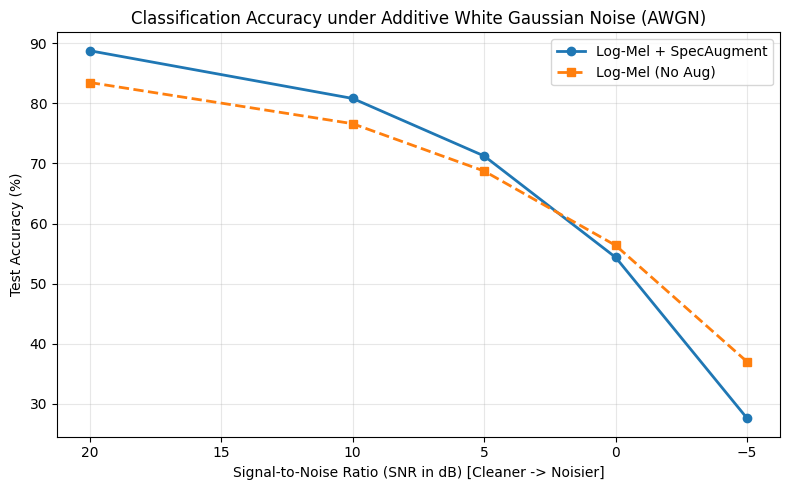


Average CPU Inference Latency: 4.32 ms per 1-second clip


In [7]:
import time
import torch
import torchaudio
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader

# --- PART A: Train & Evaluate Model 3 (MFCCs) ---
mfcc_transform = torchaudio.transforms.MFCC(
    sample_rate=SAMPLE_RATE, n_mfcc=40, melkwargs={"n_fft": 1024, "hop_length": 256, "n_mels": 64}
).to(device)

def cache_mfcc(dataset):
    feats, targets = [], []
    with torch.no_grad():
        for i in range(len(dataset)):
            waveform, _, label, *_ = dataset[i]
            if waveform.shape[1] < NUM_SAMPLES:
                waveform = F.pad(waveform, (0, NUM_SAMPLES - waveform.shape[1]))
            else:
                waveform = waveform[:, :NUM_SAMPLES]
            feats.append(mfcc_transform(waveform.to(device)).cpu())
            targets.append(labels.index(label))
    return TensorDataset(torch.stack(feats), torch.tensor(targets))

print("Caching MFCC features...")
train_mfcc_loader = DataLoader(cache_mfcc(train_set), batch_size=256, shuffle=True)
test_mfcc_loader = DataLoader(cache_mfcc(test_set), batch_size=256, shuffle=False)

model_mfcc = AudioCNN(len(labels)).to(device)
opt3 = torch.optim.Adam(model_mfcc.parameters(), lr=1e-3)
for epoch in range(15):
    model_mfcc.train()
    for x, y in train_mfcc_loader:
        x, y = x.to(device), y.to(device)
        x = time_mask_gpu(freq_mask_gpu(x))
        opt3.zero_grad()
        criterion(model_mfcc(x), y).backward()
        opt3.step()

acc_mfcc, f1_mfcc = evaluate_model(model_mfcc, test_mfcc_loader)
print(f"Model 3 (MFCC + SpecAugment)| Test Acc: {acc_mfcc:.2f}% | Macro F1: {f1_mfcc:.2f}%")

# --- PART B: Noisy Room (AWGN SNR) Robustness Test ---
snr_levels = [20, 10, 5, 0, -5]
accs_model1, accs_model2 = [], []
mel_gpu = mel_spectrogram.to(device)
db_gpu = amplitude_to_db.to(device)

print("\nRunning AWGN Noise Robustness Test...")
for snr in snr_levels:
    c1, c2, tot = 0, 0, 0
    model.eval()
    model_no_aug.eval()
    with torch.no_grad():
        for i in range(0, len(test_set), 256):
            batch_waves, batch_y = [], []
            for j in range(i, min(i + 256, len(test_set))):
                w, _, lbl, *_ = test_set[j]
                w = F.pad(w, (0, NUM_SAMPLES - w.shape[1])) if w.shape[1] < NUM_SAMPLES else w[:, :NUM_SAMPLES]
                # Add White Gaussian Noise at target SNR (dB)
                sig_pow = w.pow(2).mean() + 1e-10
                noise_pow = sig_pow / (10 ** (snr / 10))
                w_noisy = w + torch.randn_like(w) * torch.sqrt(noise_pow)
                batch_waves.append(w_noisy)
                batch_y.append(labels.index(lbl))

            specs = db_gpu(mel_gpu(torch.stack(batch_waves).to(device)))
            y_t = torch.tensor(batch_y).to(device)
            c1 += (model(specs).argmax(1) == y_t).sum().item()
            c2 += (model_no_aug(specs).argmax(1) == y_t).sum().item()
            tot += y_t.size(0)

    accs_model1.append(100 * c1 / tot)
    accs_model2.append(100 * c2 / tot)
    print(f"SNR {snr:+3d} dB | With SpecAugment: {accs_model1[-1]:.2f}% | No Aug: {accs_model2[-1]:.2f}%")

# Plot & Save SNR Curve for GitHub README
plt.figure(figsize=(8, 5))
plt.plot(snr_levels, accs_model1, marker="o", linewidth=2, label="Log-Mel + SpecAugment")
plt.plot(snr_levels, accs_model2, marker="s", linestyle="--", linewidth=2, label="Log-Mel (No Aug)")
plt.gca().invert_xaxis()
plt.title("Classification Accuracy under Additive White Gaussian Noise (AWGN)")
plt.xlabel("Signal-to-Noise Ratio (SNR in dB) [Cleaner -> Noisier]")
plt.ylabel("Test Accuracy (%)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("snr_robustness.png", dpi=150)
plt.show()

# --- PART C: Measure Single-Clip CPU Latency ---
model_cpu = AudioCNN(len(labels)).cpu().eval()
model_cpu.load_state_dict(model.state_dict())
dummy = torch.randn(1, 1, 64, 63)
# Warmup
for _ in range(10):
    _ = model_cpu(dummy)
times = []
with torch.no_grad():
    for _ in range(100):
        t0 = time.perf_counter()
        _ = model_cpu(dummy)
        times.append((time.perf_counter() - t0) * 1000)
print(f"\nAverage CPU Inference Latency: {np.mean(times):.2f} ms per 1-second clip")